# Medical Cost Analysis

**Question:** Which patient groups drive the most medical cost, and where should a health programme or insurer focus first?

This notebook checks the data, groups patients by age and BMI, and compares medical cost by smoking status, age range, BMI class, region and sex.

**Tools:** pandas, matplotlib

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.1f}".format)

## 1. Load the data

In [2]:
df = pd.read_csv("initial data.csv")
print(f"{len(df):,} rows, {df.shape[1]} columns")
df.head()

10,000 rows, 7 columns


,Age,Sex,BMI,Children,Smoker,Region,Medical Cost
0,58,male,15.6,2,yes,northwest,"17,907.5"
1,24,male,29.8,0,yes,northeast,"16,312.6"
2,50,male,29.0,5,no,northwest,"6,819.2"
3,35,male,34.0,1,no,southeast,"5,247.9"
4,31,female,17.6,3,yes,southeast,"17,525.5"


## 2. Data quality checks
Look for missing values, duplicate rows and values outside a sensible range.

In [3]:
print("Missing values per column:")
print(df.isna().sum(), "\n")
print(f"Duplicate rows: {df.duplicated().sum()}")

Missing values per column:
Age             0
Sex             0
BMI             0
Children        0
Smoker          0
Region          0
Medical Cost    0
dtype: int64 

Duplicate rows: 0


In [4]:
df.describe().loc[["min", "max"]]

,Age,BMI,Children,Medical Cost
min,18.0,15.0,0.0,"3,617.1"
max,65.0,40.0,5.0,"20,268.2"


In [5]:
# Make text columns consistent: lower case, no extra spaces
for col in ["Sex", "Smoker", "Region"]:
    df[col] = df[col].str.strip().str.lower()

for col in ["Sex", "Smoker", "Region"]:
    print(col, sorted(df[col].unique().tolist()))

Sex ['female', 'male']
Smoker ['no', 'yes']
Region ['northeast', 'northwest', 'southeast', 'southwest']


**Result:** no missing values, no duplicates, and all values are within sensible ranges (age 18 to 65, BMI 15 to 40).

## 3. Add groups
- **Age ranges** match the Excel and Power BI versions of this project.
- **BMI classes** use the standard WHO bands, with no gaps between them. (My first SQL version grouped BMI 25 to 40 together, which mixed overweight and obese patients.)

In [6]:
df["Age Range"] = pd.cut(df["Age"], bins=[0, 25, 40, 59, 120],
                         labels=["18-25", "26-40", "41-59", "60+"])

df["BMI Class"] = pd.cut(df["BMI"], bins=[0, 18.5, 25, 30, 100], right=False,
                         labels=["Underweight", "Normal", "Overweight", "Obese"])

df[["Age", "Age Range", "BMI", "BMI Class"]].head()

,Age,Age Range,BMI,BMI Class
0,58,41-59,15.6,Underweight
1,24,18-25,29.8,Overweight
2,50,41-59,29.0,Overweight
3,35,26-40,34.0,Obese
4,31,26-40,17.6,Underweight


## 4. Summaries
For each group: number of patients, average cost, total cost and share of all cost.

In [7]:
def summarise(column):
    table = df.groupby(column, observed=True)["Medical Cost"].agg(
        patients="count", avg_cost="mean", total_cost="sum")
    table["share_of_cost_%"] = table["total_cost"] / df["Medical Cost"].sum() * 100
    return table

print(f"Total medical cost: ${df['Medical Cost'].sum():,.0f}")
print(f"Average cost per patient: ${df['Medical Cost'].mean():,.0f}")

Total medical cost: $118,989,322
Average cost per patient: $11,899


### By smoking status

In [8]:
summarise("Smoker")

,patients,avg_cost,total_cost,share_of_cost_%
Smoker,,,,
no,5008,"5,894.9","29,521,434.3",24.8
yes,4992,"17,922.3","89,467,887.8",75.2


### By age range

In [9]:
summarise("Age Range")

,patients,avg_cost,total_cost,share_of_cost_%
Age Range,,,,
18-25,1648,"10,787.2","17,777,366.3",14.9
26-40,3019,"11,380.3","34,357,153.8",28.9
41-59,4093,"12,360.4","50,591,123.7",42.5
60+,1240,"13,115.9","16,263,678.4",13.7


### By BMI class

In [10]:
summarise("BMI Class")

,patients,avg_cost,total_cost,share_of_cost_%
BMI Class,,,,
Underweight,1429,"11,661.7","16,664,524.6",14.0
Normal,2604,"11,676.1","30,404,649.1",25.6
Overweight,2013,"11,865.7","23,885,703.2",20.1
Obese,3954,"12,148.3","48,034,445.2",40.4


### By region

In [11]:
summarise("Region")

,patients,avg_cost,total_cost,share_of_cost_%
Region,,,,
northeast,2514,"11,914.4","29,952,916.2",25.2
northwest,2486,"11,858.0","29,479,104.7",24.8
southeast,2479,"12,000.4","29,749,066.5",25.0
southwest,2521,"11,824.0","29,808,234.7",25.1


### By sex

In [12]:
summarise("Sex")

,patients,avg_cost,total_cost,share_of_cost_%
Sex,,,,
female,5034,"11,917.7","59,993,756.6",50.4
male,4966,"11,879.9","58,995,565.5",49.6


## 5. Charts

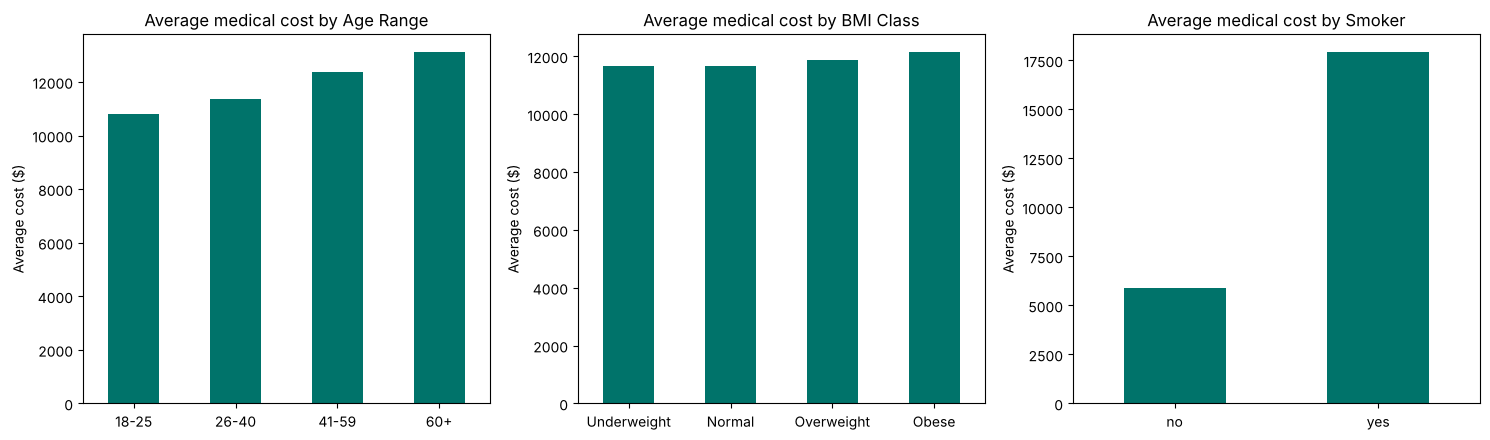

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ["Age Range", "BMI Class", "Smoker"]):
    summarise(col)["avg_cost"].plot.bar(ax=ax, color="#00736A")
    ax.set_title(f"Average medical cost by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Average cost ($)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("average_cost_charts.png", dpi=150)
plt.show()

## 6. Findings

1. **Smoking is the biggest cost driver.** Smokers cost about 3 times more than non-smokers on average ($17,922 vs $5,895). They are half the patients but 75% of total cost.
2. **Cost rises steadily with age**, from $10,787 (18 to 25) to $13,116 (60+). Ages 41 to 59 make up 42.5% of total cost, mainly because they are the largest group.
3. **Obese patients carry 40% of total cost**, but their average cost is only slightly higher than other BMI classes, so most of that share comes from group size.
4. **Region and sex make almost no difference.** All regions are within 2% of each other.

**Lesson:** totals can mislead when groups are different sizes. Comparing averages per patient is what made the smoking effect clear.

## 7. Save the cleaned data

In [14]:
df.to_csv("cleaned_medical_data.csv", index=False)
print("Saved cleaned_medical_data.csv")

Saved cleaned_medical_data.csv
